# **Phase 2 - Transfer Learning & Data Augmentations**

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.

In [2]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import time
import os
import copy

import matplotlib.pyplot as plt
import numpy as np
import torchvision

## **Overview**
1. CIFAR10 Dataset
2. Data Augmentations
3. Transfer learning with ResNet Architecture
4. Training ResNet Architecture

# **1. CIFAR10 Dataset**

This is an RGB dataset with 10 classes:

*plane, car, bird, cat, deer, dog, frog, horse, ship, truck*


## **1.1 Download and Load CIFAR10**

You can find CIFAR10 in ```torchvision.datasets.CIFAR10()``` or see [here](https://pytorch.org/vision/0.15/generated/torchvision.datasets.CIFAR10.html#torchvision.datasets.CIFAR10). Please Download the dataset and use Dataloaders to load it. This is identical to loading MNIST.

In [3]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 64

# Load CIFAR-10 training set
train_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform) #create training dataset

train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2) #wraps dataset in batches

# Load CIFAR-10 test set
testset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform) #same but for testing dataset

test_loader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Files already downloaded and verified
Files already downloaded and verified


## **1.2 Display CIFAR10 Images**

Similar to Phase 1, please complete `show_imgs()` function to display 10 images. However, this time we want to display exactly one image per class. There are 10 classes total. Show a random image per class with their label.

In [4]:
import numpy as np
import matplotlib.pyplot as plt

def show_imgs(dataloader, classes):
    dataset = dataloader.dataset 
    targets = np.array(dataset.targets)
    
    fig, axes = plt.subplots(2, 5, figsize=(12, 5)) #create figure with 2 row x 5 column grid of subplot
    for class_idx, ax in enumerate(axes.flatten()):
        idx = np.random.choice(np.where(targets == class_idx)[0]) #converts indices of all images of that class and picks one at random
        img, label = dataset[idx]
        
        img = img / 2 + 0.5
        ax.imshow(np.transpose(img.numpy(), (1, 2, 0))) #converts tensor to NumPy array, reorders axes, and draws on subplot
        ax.set_title(classes[label])
        ax.axis('off')

    plt.tight_layout()
    plt.show()

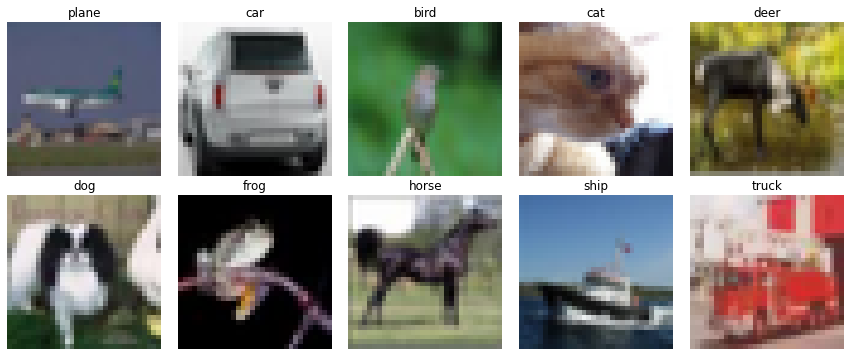

In [5]:
show_imgs(train_loader, classes)

# **2. Data Augmentations**

## **2.1 Use Built-in Augmentations**

Use augmentations from the `torchvision.transforms` library [
link](https://pytorch.org/vision/0.9/transforms.html). Apply the following. For the parameters, please test and choose suitable ones.


*   Horizontal Flip
*   Random Crop
*   Color Jitter
*   Random Resized Crop

Try each of these individually and display the augmented images using your `show_imgs()` function.

Files already downloaded and verified


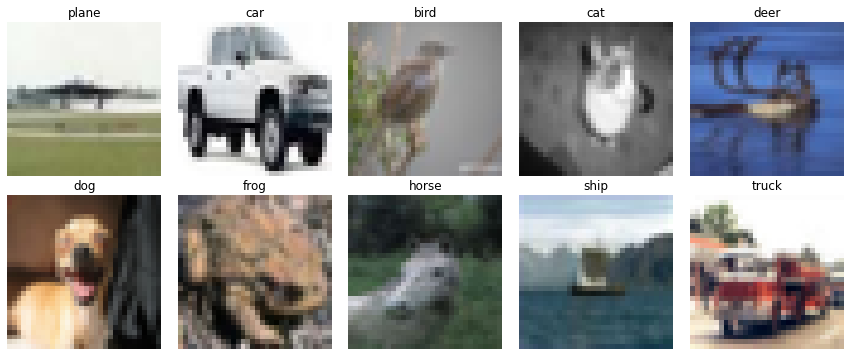

In [6]:
# Horizontal Flip
aug_transform = transforms.Compose([transforms.RandomHorizontalFlip(p=0.5),transforms.ToTensor(),transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

# Define a dataset & loader with augmentations
train_aug_loader = torch.utils.data.DataLoader(datasets.CIFAR10(root='./data', train=True, download=True, transform=aug_transform), batch_size=batch_size, shuffle=True, num_workers=2)

# Display images with augmentations
show_imgs(train_aug_loader, classes)

Files already downloaded and verified


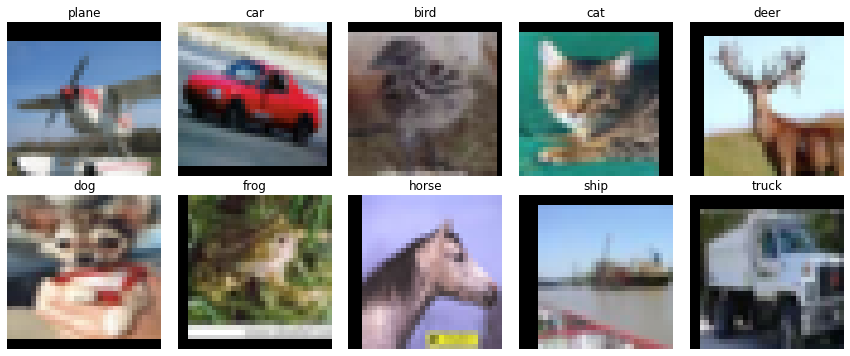

In [7]:
# Random Crop
aug_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),transforms.ToTensor(),transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Define a dataset & loader with augmentations
train_aug_loader = torch.utils.data.DataLoader(datasets.CIFAR10(root='./data', train=True, download=True, transform=aug_transform), batch_size=batch_size, shuffle=True, num_workers=2)

# Display images with augmentations
show_imgs(train_aug_loader, classes)

Files already downloaded and verified


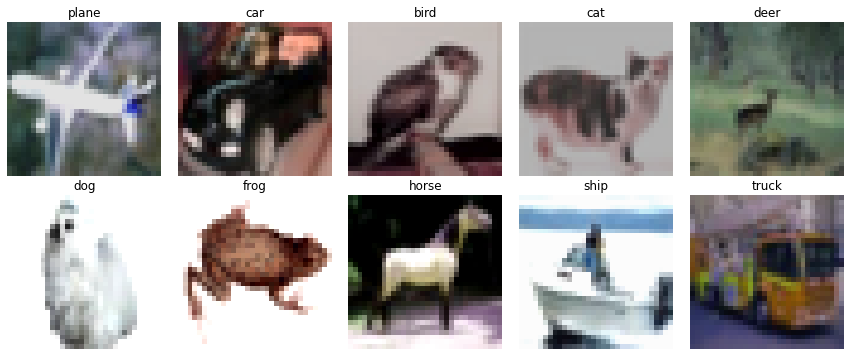

In [8]:
# Color Jitter
aug_transform = transforms.Compose([
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1), #tried numbers until it lookes fine
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Define a dataset & loader with augmentations
train_aug_loader = torch.utils.data.DataLoader(datasets.CIFAR10(root='./data', train=True, download=True, transform=aug_transform), batch_size=batch_size, shuffle=True, num_workers=2)

# Display images with augmentations
show_imgs(train_aug_loader, classes)

Files already downloaded and verified


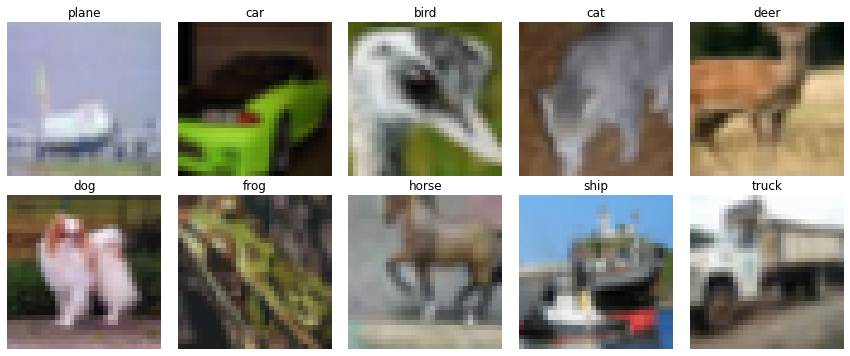

In [9]:
# Random Resized Crop
aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(32, scale=(0.6, 1.0), ratio=(0.9, 1.1)), #random crop between the parameters
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Define a dataset & loader with augmentations
train_aug_loader = torch.utils.data.DataLoader(datasets.CIFAR10(root='./data', train=True, download=True, transform=aug_transform), batch_size=batch_size, shuffle=True, num_workers=2)

# Display images with augmentations
show_imgs(train_aug_loader, classes)

### ❓ **Q 2.1.1 Please explain what Data augmentations are and their use. What is the purpose of making them random?**

Data augmentation is creating modified versions of training data using transformations that changes the way an image looks, but not what it is. Some examples that we used here were resizing, cropping, flipping, and shifting colors. Augmenting data does not change what the image is, so for example if the horse is horizontally flipped it's still a horse, but it looks different, and has differnet pixel values. This helps our training model adapt to more examples without a need for providing new data.

___
### ❓ **Q 2.1.2 Please explain all of the augmentations you are using. What is the value of each of them?**

The first is horizontal flip, all it does is mirror the image from left to right with a 50% probability. This teaches the model that an object facing left or right doesn't change it's class. A flipped car, dog, ship, or horse doesn't change the fact that it's still that animal or object.

The second is a random crop, this pads the image with 4 pixels on each side, then crops a random 32x32 window from the new image. This shifts the object up to 4 pixels in any direction, teaching the model that where the object is in the image doesn't matter, only that it's there.

The third is color jitter, and it randomly changes brightness, contrast, saturation, and hue. This makes the model understand that the lighting, color tone, and camera settings have no effect on the object, that it's still the same object.

The fourth is a random resized crop, this chooses a region in the image covering anywhere between 60-100% of the image(I used 0.6 and 1.0 as scale), nearly being a square aspect ratio, and it resizes it back to 32x32. This uses both translation and scale changes, since the crop is zoomed in. The model learns to recognize an object that can be at different sizes and levels of being zoomed.

## **2.2 Custom Augmentations**

Create a custom data augmentation function. Please do rotation, randomly between -30 and 30 degrees. You must code this yourself, do not use the torchvision function.

[This tutorial ](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) may be useful. You can use `PIL` image manupilation libraries, but NOT torchvision ones. Do not import any other libraries. You should only need:



```
from PIL import Image
import random
```





Apply this custom augmentation to the images and display the results using `show_imgs()`.

Files already downloaded and verified


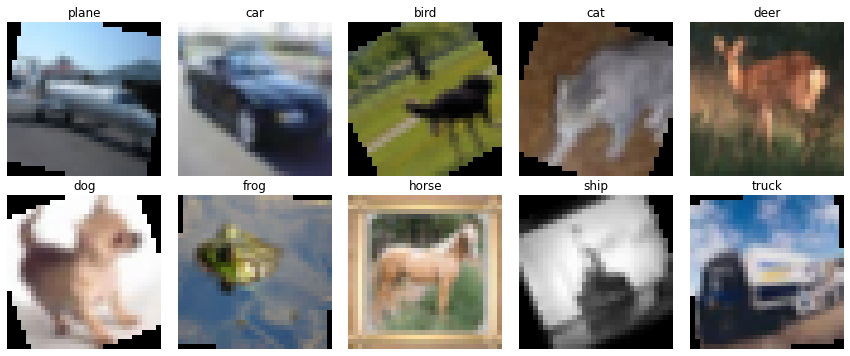

In [10]:
from PIL import Image
import random

class RandomRotate:
    def __init__(self, degrees=30): #store max rotation angle, between -30 and +30
        self.degrees = degrees

    def __call__(self, img):
        angle = random.uniform(-self.degrees, self.degrees) #random picks angle
        return img.rotate(angle, resample=Image.BILINEAR)

# Apply Transform
rotate_transform = transforms.Compose([
    RandomRotate(30),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])#Operates on PIL, converts to tensor in [0,1]

train_loader_rotate = torch.utils.data.DataLoader(datasets.CIFAR10(root='./data', train=True, download=True, transform=rotate_transform), batch_size=batch_size, shuffle=True, num_workers=2)

# Display images with the custom augmentation
show_imgs(train_loader_rotate, classes)

### ❓ **Q 2.2.1 Explain how you would determine what is a good lower and upper limit for rotation? We use -30 to 30, why does that make sense?**

Good limits on rotation are the largest range where you can still tell what the image is, still looking realisitic. Too large a rotation would cause the image to be upside down or sideways(Ex: +/- 90 degrees), too little a rotation would make the change barely noticeable at all(Ex:+/-3 degrees). We use -30 to 30 so there is a noticeable amount of tilt, but the objects are still upright enough to tell what they are supposed to be.

____

# **3. Transfer Learning**
Load ResNet18 model from ```torchvision.models.resnet18()```, make sure to load pretrained model with [weights](https://pytorch.org/vision/stable/models.html).
You will need to modify the final layer. ResNet outputs 100 labels - please change to the correct output dimension.

In [11]:
import torch
import torch.nn as nn

## **3.1 ResNet18**

In [12]:
from torchvision.models import resnet18

# Instantiate Pretrained ResNet18
model = resnet18(pretrained=True) #run through resnet18

# Modify final layer
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

# Load onto GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

# View Model to validate
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

## **3.2 Train ResNet on CIFAR10**

### **3.2.1 Train and Test Functions**
You can refer to Phase_1.ipynb to complete these functions. In ```train()```, rather than saving the accuracy and loss per iteration, you will need to save the loss and accuracy ***per epoch***. Plot loss and accuracy plots for both train and validation sets.

In [13]:
# Train Function
def train(model, train_loader, val_loader, criterion, optimizer, num_epochs, device):
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []} #create dictionary
    for epoch in range(num_epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0 #create running sums

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad() #run through training
            outputs = model(inputs) #forward pass
            loss = criterion(outputs, labels) #compute loss between logits and true labels
            loss.backward() #back propagation
            optimizer.step() #update parameters

            running_loss += loss.item() * inputs.size(0) #compute running loss
            _, preds = torch.max(outputs, 1) #takes max along dimension 1
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        history['train_loss'].append(running_loss / total) #per epoch training metrics
        history['train_acc'].append(100.0 * correct / total)

        val_loss, val_acc = test_accuracy(model, val_loader, criterion, device) #per epoch validation metrics
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print('Epoch [{}/{}]  Train Loss: {:.4f}  Train Acc: {:.2f}%  Val Loss: {:.4f}  Val Acc: {:.2f}%'.format(
            epoch + 1, num_epochs,
            history['train_loss'][-1], history['train_acc'][-1],
            val_loss, val_acc)) #print values

    return history

# Test Function
def test_accuracy(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)#similar to train, but using test inputs
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return running_loss / total, 100.0 * correct / total

# Plot Learning Curves
def plot_learning_curve(history, title=''):
    epochs = range(1, len(history['train_loss']) + 1) #plot values we found
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4)) #create one row with 2 side by side plots

    ax1.plot(epochs, history['train_loss'], label='Train') #draw training and validation loss curves
    ax1.plot(epochs, history['val_loss'], label='Validation') #label axes and adds a title with line below
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Loss'); ax1.set_title(title + ' Loss')
    ax1.legend()

    ax2.plot(epochs, history['train_acc'], label='Train') #same for accuracy curves
    ax2.plot(epochs, history['val_acc'], label='Validation')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy (%)'); ax2.set_title(title + ' Accuracy')
    ax2.legend()

    plt.tight_layout()
    plt.show()

### **3.2.2 Train and Plot Learning Curves**

Retrain the ResNet18 on CIFAR10 Dataset. You can chose the optimizer and loss function. Train first with then without data augmentation to compare. When using data augmentations, you can choose which augmentations to use!

Epoch [1/10]  Train Loss: 1.0281  Train Acc: 65.90%  Val Loss: 0.6994  Val Acc: 76.19%
Epoch [2/10]  Train Loss: 0.6447  Train Acc: 78.38%  Val Loss: 0.6517  Val Acc: 77.85%
Epoch [3/10]  Train Loss: 0.4854  Train Acc: 83.52%  Val Loss: 0.5830  Val Acc: 80.17%
Epoch [4/10]  Train Loss: 0.3793  Train Acc: 86.95%  Val Loss: 0.5931  Val Acc: 80.65%
Epoch [5/10]  Train Loss: 0.3113  Train Acc: 89.17%  Val Loss: 0.6031  Val Acc: 81.04%
Epoch [6/10]  Train Loss: 0.2484  Train Acc: 91.32%  Val Loss: 0.6186  Val Acc: 80.97%
Epoch [7/10]  Train Loss: 0.1980  Train Acc: 93.11%  Val Loss: 0.6992  Val Acc: 80.33%
Epoch [8/10]  Train Loss: 0.1712  Train Acc: 94.05%  Val Loss: 0.6782  Val Acc: 81.34%
Epoch [9/10]  Train Loss: 0.1457  Train Acc: 95.05%  Val Loss: 0.7034  Val Acc: 81.25%
Epoch [10/10]  Train Loss: 0.1164  Train Acc: 96.02%  Val Loss: 0.7428  Val Acc: 80.69%


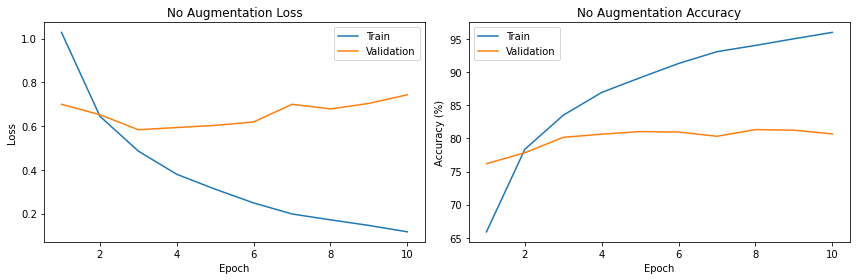

Test Loss: 0.7428  Test Acc: 80.69%


In [14]:
## TRAINING WITHOUT AUGMENTATIONS

# Define Parameters
num_epochs = 10
lr = 0.01
momentum = 0.9
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_noaug = resnet18(pretrained=True) #creates ResNet-18
model_noaug.fc = nn.Linear(model_noaug.fc.in_features, 10) #replaces last classification layer
model_noaug = model_noaug.to(device)

# Define Loss func and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_noaug.parameters(), lr=lr, momentum=momentum)

# Train Model
hist_noaug = train(model_noaug, train_loader, test_loader, criterion, optimizer, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(hist_noaug, title='No Augmentation')

# Evaluate on Test Set
test_loss, test_acc = test_accuracy(model_noaug, test_loader, criterion, device)
print('Test Loss: {:.4f}  Test Acc: {:.2f}%'.format(test_loss, test_acc))

Files already downloaded and verified
Epoch [1/10]  Train Loss: 1.3729  Train Acc: 52.62%  Val Loss: 1.1003  Val Acc: 64.93%
Epoch [2/10]  Train Loss: 1.0399  Train Acc: 64.40%  Val Loss: 0.8612  Val Acc: 71.60%
Epoch [3/10]  Train Loss: 0.9298  Train Acc: 68.24%  Val Loss: 0.7344  Val Acc: 75.11%
Epoch [4/10]  Train Loss: 0.8359  Train Acc: 71.20%  Val Loss: 0.6598  Val Acc: 77.64%
Epoch [5/10]  Train Loss: 0.7716  Train Acc: 73.44%  Val Loss: 0.6386  Val Acc: 78.21%
Epoch [6/10]  Train Loss: 0.7389  Train Acc: 74.67%  Val Loss: 0.7045  Val Acc: 75.84%
Epoch [7/10]  Train Loss: 0.7053  Train Acc: 75.75%  Val Loss: 0.5804  Val Acc: 80.08%
Epoch [8/10]  Train Loss: 0.6766  Train Acc: 76.75%  Val Loss: 0.6281  Val Acc: 78.93%
Epoch [9/10]  Train Loss: 0.6512  Train Acc: 77.68%  Val Loss: 0.6164  Val Acc: 79.58%
Epoch [10/10]  Train Loss: 0.6345  Train Acc: 78.04%  Val Loss: 0.5840  Val Acc: 80.61%


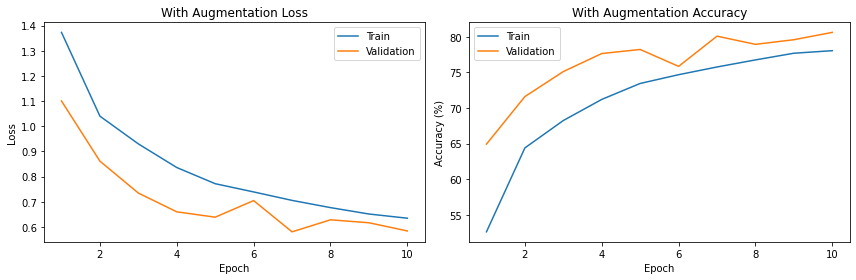

Test Loss: 0.5840  Test Acc: 80.61%


In [17]:
## TRAINING WITH AUGMENTATIONS

# Define Parameters
num_epochs = 10
full_aug_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
    RandomRotate(15),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)) #applies augmentations we used earlier in lab, everything else same
])
train_aug_loader = torch.utils.data.DataLoader(
    datasets.CIFAR10(root='./data', train=True, download=True, transform=full_aug_transform),
    batch_size=batch_size, shuffle=True, num_workers=2)

model_aug = resnet18(pretrained=True)
model_aug.fc = nn.Linear(model_aug.fc.in_features, 10)
model_aug = model_aug.to(device)

# Define Loss func and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_aug.parameters(), lr=lr, momentum=momentum)

# Train Model
hist_aug = train(model_aug, train_aug_loader, test_loader, criterion, optimizer, num_epochs, device)

# Plot Learning Curves
plot_learning_curve(hist_aug, title='With Augmentation')

# Evaluate on Test Set
test_loss, test_acc = test_accuracy(model_aug, test_loader, criterion, device)
print('Test Loss: {:.4f}  Test Acc: {:.2f}%'.format(test_loss, test_acc))

### **3.2.3 Confusion Matrix**

Write code to plot a confusion matrix after training the above ResNet18. Please make sure the axis have class names (defined in Section 1)

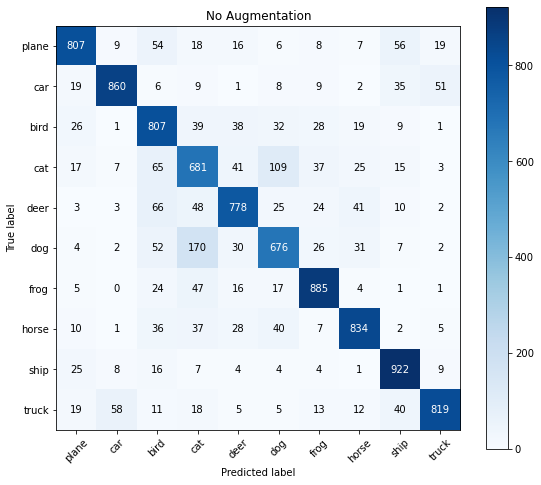

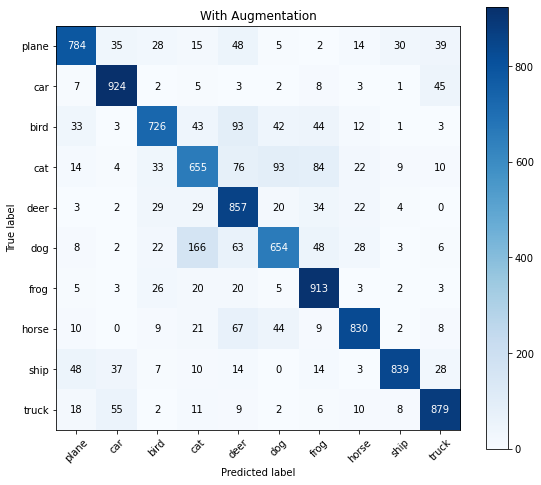

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(model, loader, classes, device, title='Confusion Matrix'):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad(): #disable gradient tracking
        for inputs, labels in loader:
            outputs = model(inputs.to(device))
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy()) #move predictions back to CPU
            all_labels.extend(labels.numpy()) 

    cm = confusion_matrix(all_labels, all_preds) #returns 10x10 array

    fig, ax = plt.subplots(figsize=(8, 7)) # create figure and displays as an image
    im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
    plt.colorbar(im)
    ax.set_xticks(np.arange(len(classes))) #one tick per class on each axis and labels
    ax.set_yticks(np.arange(len(classes)))
    ax.set_xticklabels(classes, rotation=45)
    ax.set_yticklabels(classes)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    ax.set_title(title)

    thresh = cm.max() / 2.0 #threshold at half the largest count
    for i in range(cm.shape[0]): #loops over each cell and prints count in the middle
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > thresh else 'black')

    plt.tight_layout()
    plt.show()

plot_confusion_matrix(model_aug, test_loader, classes, device, title='With Augmentation')

## **3.2.4 Freeze Network**

Initialize a new ResNet18, Freeze all the non-linear or non-fc weights. Hence, we will only be training the fc layers.

Freezing implies setting `requires_grad = False` for selected parameters


In [19]:
# Instantiate Pretrained ResNet18
resnet18_frz = models.resnet18(pretrained=True)

# Freeze all layers (except classifier/linear layers)
for param in resnet18_frz.parameters():
    param.requires_grad = False
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, 10)  #new fc layer is already trainable
resnet18_frz = resnet18_frz.to(device)

# View Model to validate
print(resnet18_frz)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
  

### **3.2.5 Train frozen ResNet18**

Retrain the frozen ResNet18 now with the same setup as the previous ResNet18 (same batch size, optimizer, learning rate, etc.) for direct comparison. The results may not be as good that is expected.

Epoch [1/10]  Train Loss: 2.2572  Train Acc: 28.04%  Val Loss: 2.2856  Val Acc: 31.32%
Epoch [2/10]  Train Loss: 2.2726  Train Acc: 29.22%  Val Loss: 2.3333  Val Acc: 30.58%
Epoch [3/10]  Train Loss: 2.2685  Train Acc: 29.22%  Val Loss: 2.6602  Val Acc: 27.92%
Epoch [4/10]  Train Loss: 2.2669  Train Acc: 28.94%  Val Loss: 2.4638  Val Acc: 29.59%
Epoch [5/10]  Train Loss: 2.2589  Train Acc: 29.35%  Val Loss: 2.4194  Val Acc: 28.30%
Epoch [6/10]  Train Loss: 2.2843  Train Acc: 29.31%  Val Loss: 2.3599  Val Acc: 28.95%
Epoch [7/10]  Train Loss: 2.2950  Train Acc: 29.19%  Val Loss: 2.5282  Val Acc: 29.07%
Epoch [8/10]  Train Loss: 2.2821  Train Acc: 29.16%  Val Loss: 2.4316  Val Acc: 29.23%
Epoch [9/10]  Train Loss: 2.2639  Train Acc: 29.04%  Val Loss: 2.4433  Val Acc: 30.61%
Epoch [10/10]  Train Loss: 2.2589  Train Acc: 29.28%  Val Loss: 2.5960  Val Acc: 28.76%


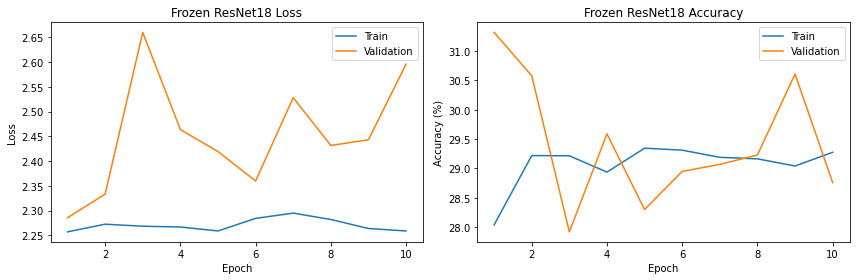

Test Loss: 2.5960  Test Acc: 28.76%


In [20]:
## TRAINING WITH or WITHOUT AUGMENTATIONS

# Define Parameters
num_epochs = 10
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(filter(lambda p: p.requires_grad, resnet18_frz.parameters()), lr=lr, momentum=momentum) # yields each parameter in the model, finds which parameters are trainable, and only keeps those ones

# Train the model
hist_frz = train(resnet18_frz, train_aug_loader, test_loader, criterion, optimizer, num_epochs, device)

# Plot the learning curve
plot_learning_curve(hist_frz, title='Frozen ResNet18')

# Evaluate on Test Set
test_loss, test_acc = test_accuracy(resnet18_frz, test_loader, criterion, device)
print('Test Loss: {:.4f}  Test Acc: {:.2f}%'.format(test_loss, test_acc))

### ❓ **Q 3.2.6 What was the difference when training with and without data augmentations?**

Both runs ended with near identical test accuracy, 80.69% without augmentation and 80.61% with it. So in my experience, there was not a significance performance improvement using augementation. Augmentation is meant to help whenever a model overfits because it acts like a regularizer. It was only trained for 10 epochs, and there was too little overfitting for the augmentation to fix. Maybe if there were more epochs we would see the augmentation provide its benefits.

___
### ❓ **Q 3.2.7 What is transfer learning and why would it be useful?**

Transfer learning is reusing a model that was already trained on a large dataset as a baseline for a new but similar task. This is useful because it needs significantly less data, the model doesn't need to learn basic features. It also trains much faster and converges in less epochs, because the starting weights are already higher quality.

___
### ❓ **Q 3.2.8 What was the difference between freezing layers and retraining all? Explain in terms of classification metrics and why you saw such metrics and confusion matrix. Is what you say as expected?**

Freezing the layers gave significantly worse results than retraining all the layers. The fully trained ResNet18 reached 28.76%. The frozen model's train accuracy stayed around 29% and training loss stay around 2.26, just below the 2.3 from random guessing, meaning that it underfit and never learned the task. The frozen backbone is unable to adapt its features to CIFAR10 because the network was pretrained on 224x224 images, but the images we had were 32x32, so the frozen features ended up being weak. When all layers are trainable, the network is able to reshape their features for smaller low-resolution images, which is it reached 80.6% test accuracy. I expected the fully trainable network to fit the new task better, and the frozen training to be faster but cost some accuracy.

___
### ❓ **Q 3.2.9 For a pretrained model like ResNet, in what general scenarios would you (1) freeze your pretrained weights adn retrain last layer, (2) retrain entire architecture, and (3) Freeze all convolution layer weights and retrain all FC layers? Explain with example scenarios if possible.**

1) I would freeze the pretrained weights and retrain only the last layer when the dataset is small and is similar the data the model was already pretrained on.
2) I would retrain the entire architecture when I have a large dataset and enough compute, or if my data is extremely different from the pretrained data.
3) I would freeze all convolution layers and retrain all FC layers if the convolutional features are good, but the classification head needs more capacity than a single linear layer in order to map them to the next task. It works well for medium sized datasets that share some similarities with the pretrained data but have a different set of labels.

___


### **3.2.10 Train frozen ResNet18 for better performance**

You may have noticed only training just the fc layer did not yield good performance. Now, you must try to investigate trying to freeze as much of the original model as possible for best results.


*   Keep fc layer unfrozen, and unfreeze the last block (in layer4 of resnet18)
*   You pick which layers to unfreeze!

Investigate the maximize the layers to unfreeze to yield best balance between performance to training time.

Epoch [1/10]  Train Loss: 1.8284  Train Acc: 36.38%  Val Loss: 1.8058  Val Acc: 40.22%
Epoch [2/10]  Train Loss: 1.6633  Train Acc: 41.22%  Val Loss: 1.5975  Val Acc: 43.49%
Epoch [3/10]  Train Loss: 1.6150  Train Acc: 42.81%  Val Loss: 1.7396  Val Acc: 44.02%
Epoch [4/10]  Train Loss: 1.5904  Train Acc: 43.69%  Val Loss: 1.6994  Val Acc: 45.82%
Epoch [5/10]  Train Loss: 1.5637  Train Acc: 44.53%  Val Loss: 1.5053  Val Acc: 47.89%
Epoch [6/10]  Train Loss: 1.5467  Train Acc: 44.80%  Val Loss: 1.6434  Val Acc: 44.94%
Epoch [7/10]  Train Loss: 1.5252  Train Acc: 45.73%  Val Loss: 1.6590  Val Acc: 47.11%
Epoch [8/10]  Train Loss: 1.5148  Train Acc: 46.07%  Val Loss: 1.6040  Val Acc: 47.03%
Epoch [9/10]  Train Loss: 1.5022  Train Acc: 46.65%  Val Loss: 1.4686  Val Acc: 48.17%
Epoch [10/10]  Train Loss: 1.4985  Train Acc: 46.77%  Val Loss: 1.4049  Val Acc: 50.48%


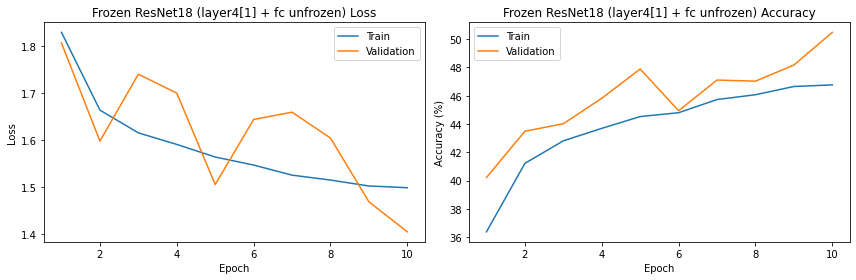

Test Loss: 1.4049  Test Acc: 50.48%


In [21]:
# Instantiate Pretrained ResNet18
resnet18_frz = models.resnet18(pretrained=True)

for param in resnet18_frz.parameters(): 
    param.requires_grad = False 
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, 10) #replaces 1000 class head with 10 layer
for param in resnet18_frz.layer4[1].parameters(): #unfreezes second basicblock of layer4, deepest convolutional stage
    param.requires_grad = True
resnet18_frz = resnet18_frz.to(device)

## TRAINING WITH or WITHOUT AUGMENTATIONS
# Define Parameters
num_epochs = 10 #same as before
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(filter(lambda p: p.requires_grad, resnet18_frz.parameters()), lr=lr, momentum=momentum)

# Train the model
hist_frz_last = train(resnet18_frz, train_aug_loader, test_loader, criterion, optimizer, num_epochs, device)

# Plot the learning curve
plot_learning_curve(hist_frz_last, title='Frozen ResNet18 (layer4[1] + fc unfrozen)')

# Evaluate on Test Set
test_loss, test_acc = test_accuracy(resnet18_frz, test_loader, criterion, device)
print('Test Loss: {:.4f}  Test Acc: {:.2f}%'.format(test_loss, test_acc))


Epoch [1/10]  Train Loss: 1.6065  Train Acc: 44.63%  Val Loss: 1.3069  Val Acc: 54.59%
Epoch [2/10]  Train Loss: 1.3540  Train Acc: 52.67%  Val Loss: 1.2340  Val Acc: 56.72%
Epoch [3/10]  Train Loss: 1.2828  Train Acc: 55.20%  Val Loss: 1.2251  Val Acc: 57.80%
Epoch [4/10]  Train Loss: 1.2385  Train Acc: 56.69%  Val Loss: 1.1230  Val Acc: 60.63%
Epoch [5/10]  Train Loss: 1.2110  Train Acc: 57.65%  Val Loss: 1.1577  Val Acc: 59.77%
Epoch [6/10]  Train Loss: 1.1854  Train Acc: 58.33%  Val Loss: 1.0870  Val Acc: 62.64%
Epoch [7/10]  Train Loss: 1.1654  Train Acc: 58.69%  Val Loss: 1.0452  Val Acc: 63.66%
Epoch [8/10]  Train Loss: 1.1444  Train Acc: 59.47%  Val Loss: 1.0996  Val Acc: 61.79%
Epoch [9/10]  Train Loss: 1.1299  Train Acc: 60.26%  Val Loss: 1.0463  Val Acc: 63.35%
Epoch [10/10]  Train Loss: 1.1105  Train Acc: 60.55%  Val Loss: 1.0357  Val Acc: 64.05%


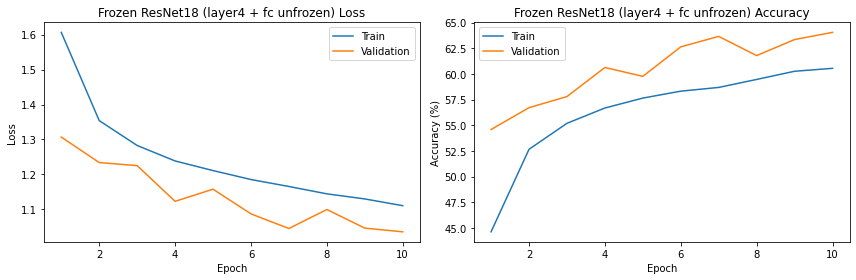

Test Loss: 1.0357  Test Acc: 64.05%


In [22]:
# Instantiate Pretrained ResNet18
resnet18_frz = models.resnet18(pretrained=True)

# Freeze whichever layers you choose for best performance
for param in resnet18_frz.parameters():
    param.requires_grad = False
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, 10)
for param in resnet18_frz.layer4.parameters(): #same as before but freezes all of layer 4 instead of just the second block
    param.requires_grad = True
resnet18_frz = resnet18_frz.to(device)

## TRAINING WITH or WITHOUT AUGMENTATIONS
# Define Parameters
num_epochs = 10
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(filter(lambda p: p.requires_grad, resnet18_frz.parameters()),
                            lr=lr, momentum=momentum)

# Train the model
hist_frz_best = train(resnet18_frz, train_aug_loader, test_loader, criterion, optimizer, num_epochs, device)

# Plot the learning curve
plot_learning_curve(hist_frz_best, title='Frozen ResNet18 (layer4 + fc unfrozen)')

# Evaluate on Test Set
test_loss, test_acc = test_accuracy(resnet18_frz, test_loader, criterion, device)
print('Test Loss: {:.4f}  Test Acc: {:.2f}%'.format(test_loss, test_acc))



### ❓ **Q 3.2.11 Which layers did you freeze to yield the best performance vs training time balance? Can you give any intuition as to why this worked well? Compare it with unfreezing only the fc layer and explain why it performs better.**

I froze conv1, bn1, layer1, layer2, and layer3, while leaving layer4 and fc trainable. This gave the best balance between setups I tried, 64.05% test accuracy compared with 28.76% for fc and 50.48% for layer4 (1) + fc being unfrozen. It was the best balance because unfreezing extra layers raise accuracy substantially, while the frozen early layer trained faster than retraining the whole network. This worked well because CNN layers learn different things. The early layers learn generic features, whereas the later layer combine into higher level features, and those need to adapt to the new dataset. Unfreezing layer4, one of those later layers, lets the network re-learn the high level features while the generic features remain frozen.

___
___
# End of Phase 2 😊🥳